# Initial data exploration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Support running from either the project root or the notebook directory.
project_root = Path.cwd()
if not (project_root / "data" / "wsh_pitches.csv").exists():
    project_root = project_root.parent

pitches = pd.read_csv(project_root / "data" / "wsh_pitches.csv")
pitches.head()

,batter_id,pitcher_id,throw_side,bat_side,is_fb,is_in_zone,is_swing,is_miss
0,1,200,R,R,0,0,1,1
1,1,30,L,R,1,0,1,0
2,1,27,R,R,0,0,0,0
3,1,91,L,R,0,1,1,0
4,1,83,R,R,0,0,0,0


### Data missingness checks and confirming binary columns

In [2]:
total_pitches = len(pitches)
print(f"Total pitches: {total_pitches:,}")

rate_columns = ["is_fb", "is_in_zone", "is_swing", "is_miss"]
display(pitches.isna().sum().rename("missing_count").to_frame())
display(pitches[rate_columns].agg(["min", "max"]))

assert not pitches.isna().any().any(), "Review missing values before computing fractions."
assert pitches[rate_columns].isin([0, 1]).all().all()
assert pitches[["throw_side", "bat_side"]].isin(["L", "R"]).all().all()
assert (pitches["is_miss"] <= pitches["is_swing"]).all()

Total pitches: 94,495


,missing_count
batter_id,0
pitcher_id,0
throw_side,0
bat_side,0
is_fb,0
is_in_zone,0
is_swing,0
is_miss,0


,is_fb,is_in_zone,is_swing,is_miss
min,0,0,0,0
max,1,1,1,1


### Splits by bat/throw side

In [3]:
throw_counts = pitches["throw_side"].value_counts().sort_index()
throw_summary = pd.DataFrame({
    "pitch_count": throw_counts,
    "fraction": throw_counts / total_pitches,
})
throw_summary

,pitch_count,fraction
throw_side,,
L,20345,0.215302
R,74150,0.784698


In [4]:
bat_counts = pitches["bat_side"].value_counts().sort_index()
bat_summary = pd.DataFrame({
    "pitch_count": bat_counts,
    "fraction": bat_counts / total_pitches,
})
bat_summary

,pitch_count,fraction
bat_side,,
L,34126,0.361141
R,60369,0.638859


In [5]:
handedness_counts = pitches.groupby(["throw_side", "bat_side"]).size()
handedness_summary = pd.DataFrame({
    "pitch_count": handedness_counts,
    "fraction": handedness_counts / total_pitches,
})
handedness_summary

pitch_count  fraction
throw_side bat_side                       
L          L                4591  0.048585
           R               15754  0.166718
R          L               29535  0.312556
           R               44615  0.472141

### Pitch fractions, overall and by platoon

`contact_rate` = (swings − misses) / swings, computed within each group. It is undefined (NaN) for groups with no swings. The other fractions use all pitches as the denominator.

In [6]:
rate_names = {
    "is_fb": "fastball_fraction",
    "is_in_zone": "in_zone_fraction",
    "is_swing": "swing_fraction",
    "is_miss": "swing_and_miss_fraction",
}
overall_rates = pitches[rate_columns].mean().rename(index=rate_names)
swing_count = pitches["is_swing"].sum()
miss_count = pitches["is_miss"].sum()
overall_rates["contact_rate"] = (
    (swing_count - miss_count) / swing_count if swing_count > 0 else float("nan")
)
overall_rates.to_frame("fraction")

,fraction
fastball_fraction,0.539129
in_zone_fraction,0.489931
swing_fraction,0.523541
swing_and_miss_fraction,0.207408
contact_rate,0.603837


In [7]:
rates_by_throw = pitches.groupby("throw_side")[rate_columns].mean().rename(columns=rate_names)
rates_by_throw.insert(0, "pitch_count", throw_counts)

swing_miss_counts = pitches.groupby("throw_side")[["is_swing", "is_miss"]].sum()
rates_by_throw["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_throw

,pitch_count,fastball_fraction,in_zone_fraction,swing_fraction,swing_and_miss_fraction,contact_rate
throw_side,,,,,,
L,20345,0.495896,0.482576,0.421283,0.136495,0.676000
R,74150,0.550991,0.491949,0.551598,0.226864,0.588714


In [8]:
rates_by_bat = pitches.groupby("bat_side")[rate_columns].mean().rename(columns=rate_names)
rates_by_bat.insert(0, "pitch_count", bat_counts)

swing_miss_counts = pitches.groupby("bat_side")[["is_swing", "is_miss"]].sum()
rates_by_bat["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_bat

,pitch_count,fastball_fraction,in_zone_fraction,swing_fraction,swing_and_miss_fraction,contact_rate
bat_side,,,,,,
L,34126,0.545625,0.491356,0.486345,0.097287,0.799964
R,60369,0.535457,0.489125,0.544568,0.269658,0.504821


In [9]:
rates_by_matchup = (
    pitches.groupby(["throw_side", "bat_side"])[rate_columns]
    .mean()
    .rename(columns=rate_names)
)
rates_by_matchup.insert(0, "pitch_count", handedness_counts)

swing_miss_counts = pitches.groupby(["throw_side", "bat_side"])[["is_swing", "is_miss"]].sum()
rates_by_matchup["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_matchup

pitch_count  fastball_fraction  in_zone_fraction  \
throw_side bat_side                                                     
L          L                4591           0.492267          0.478545   
           R               15754           0.496953          0.483750   
R          L               29535           0.553919          0.493347   
           R               44615           0.549053          0.491023   

                     swing_fraction  swing_and_miss_fraction  contact_rate  
throw_side bat_side                                                         
L          L               0.630146                 0.380091      0.396820  
           R               0.360416                 0.065507      0.818246  
R          L               0.463992                 0.053327      0.885070  
           R               0.609593                 0.341746      0.439387

### Pitches per pitcher, batter, and pitcher–batter pair

In [10]:
pitcher_counts = pitches.groupby("pitcher_id").size().rename("pitch_count")
batter_counts = pitches.groupby("batter_id").size().rename("pitch_count")
pair_counts = pitches.groupby(["pitcher_id", "batter_id"]).size().rename("pitch_count")

print(f"Unique pitchers: {len(pitcher_counts):,}")
print(f"Unique batters: {len(batter_counts):,}")
print(f"Unique pitcher–batter pairs: {len(pair_counts):,}")

pd.DataFrame({
    "pitcher": pitcher_counts.describe(),
    "batter": batter_counts.describe(),
    "pitcher_batter_pair": pair_counts.describe(),
})

Unique pitchers: 200
Unique batters: 200
Unique pitcher–batter pairs: 31,498


,pitcher,batter,pitcher_batter_pair
count,200.000000,200.000000,31498.000000
mean,472.475000,472.475000,3.000032
std,37.270563,284.569037,1.982357
min,404.000000,49.000000,1.000000
25%,447.000000,215.500000,1.000000
50%,464.000000,437.000000,3.000000
75%,486.250000,717.250000,4.000000
max,576.000000,1005.000000,16.000000


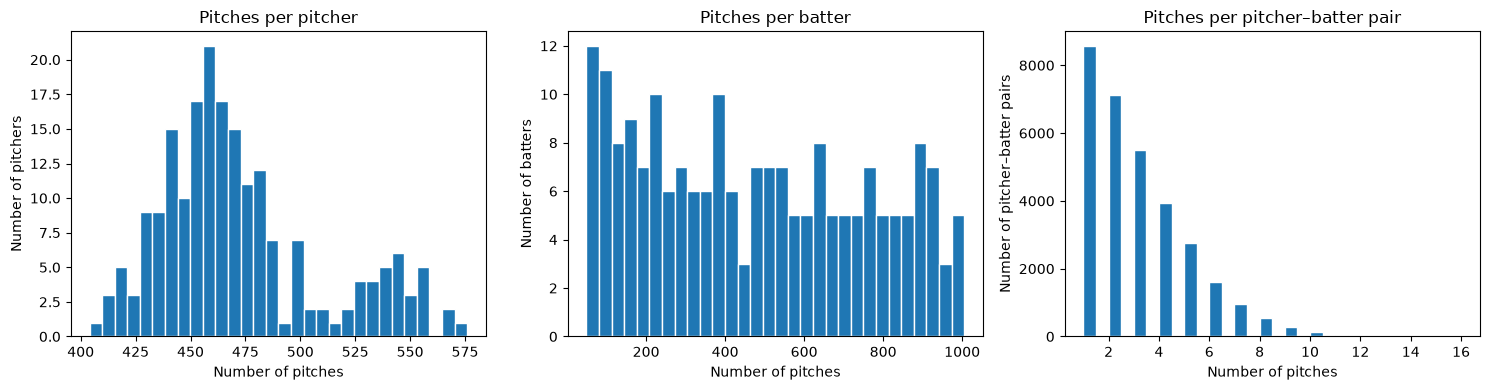

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, counts, label in zip(
    axes,
    [pitcher_counts, batter_counts, pair_counts],
    ["pitcher", "batter", "pitcher–batter pair"],
):
    ax.hist(counts, bins=30, edgecolor="white")
    ax.set_title(f"Pitches per {label}")
    ax.set_xlabel("Number of pitches")
    ax.set_ylabel(f"Number of {label}s")

fig.tight_layout()
plt.show()

So far, all the data looks reasonable and as expected, with one exception: contact rates appear to be more extreme than expected based on platoon matchups (in both directions). Same-side matchups have considerably lower contact rates than I'd expect (despite the fact that they're same-side matchups and therefore favor the pitcher), and opposite-side matchups have considerably higher contract rates than I'd expect (also despite the fact that they're opposite-side matchups and therefore favor the batter). Swing rates also look more extreme by platoon than I'd expect, though to a lesser degree. Since this is the data provided for this project, I'll treat it as ground truth, but this is something I'll want to keep flagged mentally as I evaluate the model I eventually build within the context of baseball models I've typically seen/built before.

Before proceeding with any actual modeling choices, I want to do one further investigation for the platoon contact discrepancy. Is there something more specific going on with IZ vs OOZ swing/contact rates, or does my current observation of the contact rate that isn't conditioned on IZ/OOZ hold for both?

In [12]:
# Compare swing/contact rates within each zone and platoon matchup.
# Swing fraction uses pitches; contact rate uses swings as its denominator.
zone_matchup_groups = pitches.groupby(["is_in_zone", "throw_side", "bat_side"])
zone_matchup_rates = zone_matchup_groups.agg(
    pitch_count=("is_swing", "size"),
    swing_count=("is_swing", "sum"),
    miss_count=("is_miss", "sum"),
    swing_fraction=("is_swing", "mean"),
)
zone_matchup_rates["contact_rate"] = (
    (zone_matchup_rates["swing_count"] - zone_matchup_rates["miss_count"])
    / zone_matchup_rates["swing_count"].where(zone_matchup_rates["swing_count"] > 0)
)
zone_matchup_rates = zone_matchup_rates.rename(
    index={0: "OOZ", 1: "IZ"}, level="is_in_zone"
).rename_axis(index={"is_in_zone": "zone"})
zone_matchup_rates


pitch_count  swing_count  miss_count  \
zone throw_side bat_side                                         
OOZ  L          L                2394         1671        1073   
                R                8133         1886         559   
     R          L               14964         3942         598   
                R               22708        15196        9188   
IZ   L          L                2197         1222         672   
                R                7621         3792         473   
     R          L               14571         9762         977   
                R               21907        12001        6059   

                          swing_fraction  contact_rate  
zone throw_side bat_side                                
OOZ  L          L               0.697995      0.357870  
                R               0.231895      0.703606  
     R          L               0.263432      0.848300  
                R               0.669191      0.395367  
IZ   L          L               0.556213      0.450082  
                R               0.497572      0.875264  
     R          L               0.669961      0.899918  
                R               0.547816      0.495125

Looks like this observation holds true across both IZ and OOZ. I'll proceed with my modeling as if this were ground truth for now, but I'll keep my eye out for what (potential) strange implications this has on my model downstream.

## Contact modeling: target, assumptions, and configuration

We treat the supplied data, including its unusual platoon contact patterns, as ground truth. The target is **P(contact | swing, batter ID, pitcher ID, batting side, throwing side, in-zone status, fastball status)**. Takes are excluded from the likelihood. All four context features (bat/throw side, IZ, and FB) and their interactions enter immediately through 16 population context logits. Shared batter and pitcher intercepts pool across contexts; there are no player-specific context slopes.

For swing *i*, contact is Bernoulli with logit probability `context_logit + batter_effect + pitcher_effect`. Context logits have independent N(0, 2.5²) priors (this would be treated as a hyperparameter to tune in a more robust version of this analysis). Player effects have independent N(0, 1 / precision) priors; batter and pitcher precisions are selected on validation log loss. The likelihood assumes conditional independence and stable player ability. This is a Gaussian-shrinkage MAP fit with a conditional Laplace approximation, not MCMC.

The proper priors resolve the additive likelihood's non-identifiability. For interpretation, player effects are subsequently centered within their observed handedness, and the group means absorbed into context logits. **Neutral opposition** means zero centered deviation: the equal-player mean logit effect within the requested side, rather than the particular opponents a hitter faced. Neutral-player uncertainty includes the uncertainty in that group mean, not the variability of a randomly selected actual opponent.

Keep the existing `.venv` and dependencies. Run this notebook from the project root or `notebook/`. Seeds, split assignments, selected settings, scores, and fitted coefficients are saved under ignored `outputs/contact_model/`.

In [13]:
import hashlib
import json
import sys
from itertools import product
from time import perf_counter

import numpy as np
from scipy.special import expit
from threadpoolctl import threadpool_limits

# Bound BLAS threads for these small matrix operations; no GPU is needed.
blas_limit = threadpool_limits(limits=1, user_api="blas")
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))
from contact_model import (
    CONTEXT,
    CONTEXT_LEVELS,
    ContactModel,
    batter_projection,
    pair_sensitivity_split,
    performance,
    predictive_context_check,
    prepare_swings,
    reference_contexts,
    reliability,
    select_shrinkage,
    simulation_recovery,
    split_swings,
    subgroup_performance,
)

SPLIT_SEED = 42
DRAW_SEED = 44
PRECISION_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
CONTEXT_SD = 2.5
VALIDATION_TOLERANCE = 0.001
POSTERIOR_DRAWS = 2000
SIMULATION_REPETITIONS = 20
output_dir = project_root / "outputs" / "contact_model"
output_dir.mkdir(parents=True, exist_ok=True)
swings = prepare_swings(pitches)
print(f"Modeling {len(swings):,} swings from {len(pitches):,} pitches.")

Modeling 49,472 swings from 94,495 pitches.


### Train / validation / test: individual coverage

Use a 60/20/20 swing-level split stratified by the 16 contexts. Require every batter and pitcher in every partition; seed retries depend only on IDs and context, never contact outcomes. Player context-specific coverage is not required. Player encodings and model fitting use training data only.

The primary target is additional swings involving known players. Pairs may cross partitions, so residual matchup dependence may make this evaluation optimistic; a separate pair-grouped sensitivity check uses development data only. No dates or game identifiers are available, so neither design establishes chronological or game-independent forecast performance.

In [14]:
train, validation, test, used_split_seed = split_swings(swings, SPLIT_SEED)
development = pd.concat([train, validation]).sort_index()
assert set(train.index).isdisjoint(validation.index)
assert set(development.index).isdisjoint(test.index)
assert set(development.index) | set(test.index) == set(swings.index)

split_summary = pd.DataFrame({
    name: {
        "swings": len(frame),
        "batters": frame.batter_id.nunique(),
        "pitchers": frame.pitcher_id.nunique(),
        "min_batter_swings": frame.groupby("batter_id").size().min(),
        "min_pitcher_swings": frame.groupby("pitcher_id").size().min(),
    }
    for name, frame in [("train", train), ("validation", validation), ("test", test)]
}).T
display(split_summary)
display(pd.concat({
    name: frame.groupby(CONTEXT).size()
    for name, frame in [("train", train), ("validation", validation), ("test", test)]
}, axis=1))

split_assignment = pd.concat([
    pd.Series(name, index=frame.index)
    for name, frame in [("train", train), ("validation", validation), ("test", test)]
]).sort_index().rename("partition")
split_assignment.rename_axis("original_pitch_row").to_csv(output_dir / "split_assignments.csv")
print(f"Frozen split seed: {used_split_seed}. No test outcomes are used in selection.")

,swings,batters,pitchers,min_batter_swings,min_pitcher_swings
train,29682,200,200,10,36
validation,9895,200,200,2,10
test,9895,200,200,3,7


train  validation  test
bat_side throw_side is_in_zone is_fb                         
L        L          0          0        500         166   167
                               1        502         168   168
                    1          0        326         109   109
                               1        407         136   135
         R          0          0        950         317   317
                               1       1414         472   472
                    1          0       2365         788   788
                               1       3493        1164  1164
R        L          0          0        580         193   193
                               1        552         184   184
                    1          0       1022         341   341
                               1       1252         418   418
         R          0          0       4035        1345  1345
                               1       5083        1694  1694
                    1          0       2914         971   971
                               1       4287        1429  1429

Frozen split seed: 42. No test outcomes are used in selection.


### Validation-selected shrinkage and meaningful baselines

Compare an overall contact-rate baseline, a context-only model, a context-plus-batter model, and the context-plus-batter-plus-pitcher model. Tune batter-only precision separately and use a small Cartesian grid for the full model. Scores use unweighted swings; also report batter-balanced scores. The agreed full architecture is retained, with its precisions selected using validation log loss. Among settings within 0.001 of the minimum, prefer the strongest overall shrinkage (smallest summed player-effect prior variance). This protects against weakly identified scales when negligible score differences favor nearly unregularized estimates. Test outcomes are not inspected here.

The summed likelihood makes precision an absolute prior precision: standard deviation is `1 / sqrt(precision)`. This is not a regularization strength that is rescaled by sample size. Very similar validation scores should not be interpreted as precise identification of the shrinkage scale.

The candidate table displays `summed_prior_variance = 1 / batter_precision + 1 / pitcher_precision`, the log-loss gap from the best score, tolerance eligibility, and the selected row. A smaller summed variance means stronger overall prior shrinkage; it is a selection-strength metric, not an observed percentage of shrinkage for any individual player.

,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
Overall,9895.0,0.669323,0.238180,0.500000,0.664033,0.235571,0.609096,0.600027,0.009069
Context,9895.0,0.557449,0.190218,0.750346,0.571578,0.196560,0.609096,0.600009,0.009087
Context + batter,9895.0,0.507268,0.169292,0.816275,0.513784,0.172430,0.609096,0.602408,0.006687
Context + batter + pitcher,9895.0,0.442203,0.144147,0.866552,0.450361,0.147390,0.609096,0.606133,0.002963


batter_precision,pitcher_precision,log_loss,log_loss_gap,summed_prior_variance,within_tolerance,selected
1.000000,0.010000,0.441906,0.000000,101.00,True,False
1.000000,0.100000,0.441922,0.000016,11.00,True,False
1.000000,1.000000,0.442203,0.000297,2.00,True,True
0.100000,0.010000,0.442409,0.000503,110.00,True,False
0.100000,0.100000,0.442413,0.000507,20.00,True,False
0.100000,1.000000,0.442622,0.000716,11.00,True,False
0.010000,0.100000,0.442839,0.000933,110.00,True,False
0.010000,0.010000,0.442840,0.000934,200.00,True,False
0.010000,1.000000,0.443037,0.001131,101.00,False,False
10.000000,0.010000,0.447290,0.005384,100.10,False,False


Chosen log-loss gap: 0.000297 (tolerance 0.001); summed prior variance: 2.00. This is the smallest summed variance among eligible candidates.
Selected precisions: batter=1, pitcher=1
Selection runtime: 8.7 seconds


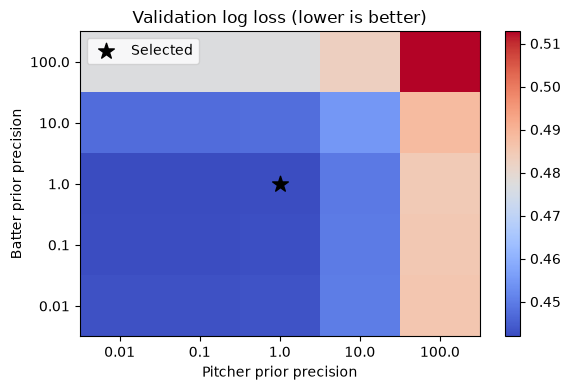

In [15]:
selection_start = perf_counter()
context_training_model = ContactModel(
    include_batter=False, include_pitcher=False, context_sd=CONTEXT_SD
).fit(train)
validation_baselines = {
    "Overall": performance(validation, np.full(len(validation), train.contact.mean())),
    "Context": performance(validation, context_training_model.predict(validation)),
}

batter_trials = []
for precision in PRECISION_GRID:
    fitted = ContactModel(
        batter_precision=precision, include_pitcher=False, context_sd=CONTEXT_SD
    ).fit(train)
    batter_trials.append({
        "batter_precision": precision,
        **performance(validation, fitted.predict(validation)),
    })
batter_selection = pd.DataFrame(batter_trials).sort_values("log_loss")
chosen_batter_only = select_shrinkage(batter_selection, VALIDATION_TOLERANCE)
chosen_batter_only_precision = float(chosen_batter_only.batter_precision)
validation_baselines["Context + batter"] = chosen_batter_only.drop("batter_precision").to_dict()

full_trials = []
for batter_precision, pitcher_precision in product(PRECISION_GRID, repeat=2):
    fitted = ContactModel(batter_precision, pitcher_precision, context_sd=CONTEXT_SD).fit(train)
    full_trials.append({
        "batter_precision": batter_precision,
        "pitcher_precision": pitcher_precision,
        "fit_seconds": fitted.fit_seconds,
        "max_gradient": fitted.gradient_max,
        **performance(validation, fitted.predict(validation)),
    })
shrinkage_selection = pd.DataFrame(full_trials).sort_values("log_loss")
chosen = select_shrinkage(shrinkage_selection, VALIDATION_TOLERANCE)
chosen_batter_precision = float(chosen.batter_precision)
chosen_pitcher_precision = float(chosen.pitcher_precision)
validation_baselines["Context + batter + pitcher"] = chosen.drop(
    ["batter_precision", "pitcher_precision", "fit_seconds", "max_gradient"]
).to_dict()
validation_scores = pd.DataFrame(validation_baselines).T

shrinkage_selection["summed_prior_variance"] = (
    1 / shrinkage_selection.batter_precision + 1 / shrinkage_selection.pitcher_precision
)
shrinkage_selection["log_loss_gap"] = shrinkage_selection.log_loss - shrinkage_selection.log_loss.min()
shrinkage_selection["within_tolerance"] = (
    shrinkage_selection.log_loss <= shrinkage_selection.log_loss.min() + VALIDATION_TOLERANCE
)
shrinkage_selection["selected"] = (
    shrinkage_selection.batter_precision.eq(chosen_batter_precision)
    & shrinkage_selection.pitcher_precision.eq(chosen_pitcher_precision)
)
display(validation_scores)
display(shrinkage_selection[[
    "batter_precision", "pitcher_precision", "log_loss", "log_loss_gap",
    "summed_prior_variance", "within_tolerance", "selected",
]].style.format({
    "log_loss": "{:.6f}", "log_loss_gap": "{:.6f}", "summed_prior_variance": "{:.2f}",
}).hide(axis="index"))
print(
    f"Chosen log-loss gap: {chosen.log_loss - shrinkage_selection.log_loss.min():.6f} "
    f"(tolerance {VALIDATION_TOLERANCE:g}); summed prior variance: "
    f"{1 / chosen_batter_precision + 1 / chosen_pitcher_precision:.2f}. "
    "This is the smallest summed variance among eligible candidates."
)
print(f"Selected precisions: batter={chosen_batter_precision:g}, pitcher={chosen_pitcher_precision:g}")
print(f"Selection runtime: {perf_counter() - selection_start:.1f} seconds")
if any(value in [min(PRECISION_GRID), max(PRECISION_GRID)] for value in [chosen_batter_precision, chosen_pitcher_precision]):
    print("A chosen precision is at a grid boundary; inspect score sensitivity before treating it as well determined.")
shrinkage_selection.to_csv(output_dir / "shrinkage_validation.csv", index=False)
validation_scores.to_csv(output_dir / "validation_scores.csv")

fig, ax = plt.subplots(figsize=(6, 4))
grid = shrinkage_selection.pivot(index="batter_precision", columns="pitcher_precision", values="log_loss")
image = ax.imshow(grid.to_numpy(), aspect="auto", origin="lower", cmap="coolwarm")
ax.scatter(grid.columns.get_loc(chosen_pitcher_precision), grid.index.get_loc(chosen_batter_precision), marker="*", s=140, color="black", label="Selected")
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel("Pitcher prior precision")
ax.set_ylabel("Batter prior precision")
ax.set_title("Validation log loss (lower is better)")
ax.legend(loc="upper left")
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

### Pair-grouped sensitivity check on development data

This check changes the evaluation target to held-out pitcher–batter combinations. It uses no primary test rows and does not select the primary penalties. Its scores are descriptive: selected penalties were informed by outcomes in the development set, so this is not an additional untouched evaluation. Check individual coverage; if absent players occur, report them instead of silently substituting zero-uncertainty estimates.

In [16]:
pair_train, pair_validation = pair_sensitivity_split(development, seed=43)
train_pairs = set(map(tuple, pair_train[["batter_id", "pitcher_id"]].to_numpy()))
validation_pairs = set(map(tuple, pair_validation[["batter_id", "pitcher_id"]].to_numpy()))
assert train_pairs.isdisjoint(validation_pairs)
missing_pair_players = {
    key: set(pair_validation[key]) - set(pair_train[key])
    for key in ["batter_id", "pitcher_id"]
}
print("Players absent from sensitivity training:", missing_pair_players)
if any(missing_pair_players.values()):
    print("Sensitivity scoring skipped: evaluating unseen players needs an explicit population-predictive treatment.")
    pair_scores = pd.DataFrame()
else:
    pair_context = ContactModel(include_batter=False, include_pitcher=False, context_sd=CONTEXT_SD).fit(pair_train)
    pair_model = ContactModel(chosen_batter_precision, chosen_pitcher_precision, context_sd=CONTEXT_SD).fit(pair_train)
    pair_scores = pd.DataFrame({
        "Context": performance(pair_validation, pair_context.predict(pair_validation)),
        "Context + batter + pitcher": performance(pair_validation, pair_model.predict(pair_validation)),
    }).T
    display(pair_scores)
    pair_scores.to_csv(output_dir / "pair_sensitivity_scores.csv")

Players absent from sensitivity training: {'batter_id': set(), 'pitcher_id': set()}


,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
Context,10029.0,0.566901,0.193577,0.747043,0.582265,0.199991,0.598863,0.603479,-0.004615
Context + batter + pitcher,10029.0,0.453076,0.148253,0.860865,0.461294,0.151351,0.598863,0.600884,-0.002020


### Refit the frozen specification and approximate uncertainty

Refit on train + validation. The test set remains excluded from all fitting and the reference mixtures conditioned on batting side. Keep this development fit for both evaluation and the batter lookup; there is no silent all-data refit.

For coefficients θ, a quadratic expansion of the log posterior around the MAP estimate gives `θ | data ≈ N(θ_MAP, H⁻¹)`, where H is the negative-log-posterior Hessian. Draw **jointly**, preserving population/player covariance. Intervals are approximate credible intervals conditional on validation-selected precision, the architecture, and the fixed reference weights. They omit uncertainty in selection and future pitch mix, and do not account for model misspecification. They describe a probability, not the realized outcome of an individual swing.

For each batting side, estimate the joint pitcher-handedness × FB distribution among that side's in-zone development swings. Weights sum to one within batting side. All hitters of the same side use the same mix, while LHH and RHH can face different typical opposition. Restrict and renormalize those weights for the LHP-only answer. We do not model an in-zone frequency in this mix: all three requested outputs condition on being in zone. The display also reports the resulting LHP share for each batting side.

In [17]:
final_models = {
    "Context": ContactModel(include_batter=False, include_pitcher=False, context_sd=CONTEXT_SD).fit(development),
    "Context + batter": ContactModel(chosen_batter_only_precision, include_pitcher=False, context_sd=CONTEXT_SD).fit(development),
    "Context + batter + pitcher": ContactModel(chosen_batter_precision, chosen_pitcher_precision, context_sd=CONTEXT_SD).fit(development),
}
contact_model = final_models["Context + batter + pitcher"]
contact_model.laplace_covariance(development)
coefficient_draws = contact_model.draw_coefficients(POSTERIOR_DRAWS, DRAW_SEED)
reference_mix = reference_contexts(development)
display(reference_mix)
assert np.allclose(reference_mix.groupby("bat_side").weight.sum(), 1)
lhp_reference_share = reference_mix.loc[reference_mix.throw_side.eq("L")].groupby("bat_side").weight.sum()
display(lhp_reference_share.rename("LHP_share_of_IZ_swings").to_frame())
print(f"Parameters: {contact_model.n_parameters}; iterations: {contact_model.iterations}")
print(f"Max absolute gradient: {contact_model.gradient_max:.3g}")
print(f"Hessian condition number: {contact_model.hessian_condition:.1f}")

import scipy
import sklearn

run_settings = {
    "target": "contact conditional on swing", "split_seed": used_split_seed,
    "split": "60/20/20 swings stratified by context with individual coverage",
    "precision_grid": PRECISION_GRID, "validation_tolerance": VALIDATION_TOLERANCE, "batter_precision": chosen_batter_precision,
    "pitcher_precision": chosen_pitcher_precision,
    "batter_only_precision": chosen_batter_only_precision,
    "context_prior_sd": CONTEXT_SD, "draw_seed": DRAW_SEED,
    "posterior_draws": POSTERIOR_DRAWS,
    "simulation_repetitions": SIMULATION_REPETITIONS,
    "data_sha256": hashlib.sha256((project_root / "data" / "wsh_pitches.csv").read_bytes()).hexdigest(),
    "python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit_learn": sklearn.__version__,
    "fit_rows": len(development), "test_rows": len(test),
    "neutral_opposition": "equal-player mean logit effect within handedness",
    "reference_mix": "throw_side x is_fb conditional on bat_side and in-zone swings; development only",
    "limitations": ["no chronological validation", "conditional Laplace intervals", "historical swing mix shared within batting side"],
}
(output_dir / "run_settings.json").write_text(json.dumps(run_settings, indent=2) + "\n")
reference_mix.to_csv(output_dir / "reference_mix.csv", index=False)
np.savez_compressed(
    output_dir / "development_fit.npz",
    coefficients=contact_model.theta, covariance=contact_model.covariance,
    batter_ids=contact_model.player_ids["batter_id"],
    pitcher_ids=contact_model.player_ids["pitcher_id"],
    batter_sides=contact_model.player_sides["batter_id"],
    pitcher_sides=contact_model.player_sides["pitcher_id"],
    precision=contact_model.precision,
)

,bat_side,throw_side,is_fb,swings,weight
0,L,L,0,435,0.049499
1,L,L,1,543,0.061789
2,L,R,0,3153,0.358785
3,L,R,1,4657,0.529927
4,R,L,0,1363,0.107883
5,R,L,1,1670,0.132183
6,R,R,0,3885,0.307504
7,R,R,1,5716,0.452430


,LHP_share_of_IZ_swings
bat_side,
L,0.111288
R,0.240066


Parameters: 416; iterations: 185
Max absolute gradient: 0.000913
Hessian condition number: 1511.4


### Prior plausibility and simulation recovery

The prior predictive check below uses the selected precision scales and declared context prior. Because scales were selected using validation outcomes, this is a check of the working prior assumptions rather than a pre-data prior elicitation.

Recovery simulation holds the real development matchup/context structure fixed, samples Gaussian player effects at the selected scales, and generates Bernoulli contacts. It checks the neutral-pitcher IZ fastball/LHP target for all batters, including sparse players. Twenty replications are a modest diagnostic. Report coverage by replication and sample-size band; players within a replication share estimated context effects, so the thousands of player results are not independent trials. Passing this check does not establish coverage with misspecification or account for penalty selection.

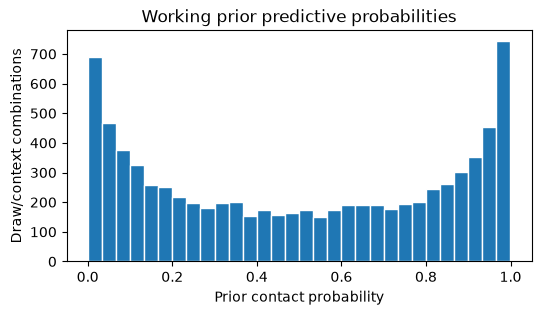

Prior probability quantiles: [0.00300216 0.49876878 0.99722623]


,estimates,coverage_95,mean_error,mean_interval_width
sample_band,,,,
<50,580,0.948276,-0.000135,0.229253
50–199,1760,0.950568,0.000727,0.120653
200+,1660,0.963253,-0.000115,0.081854


Coverage across replications:


count    20.000000
mean      0.955500
std       0.016456
min       0.925000
25%       0.945000
50%       0.960000
75%       0.970000
max       0.980000
Name: covered_95, dtype: float64

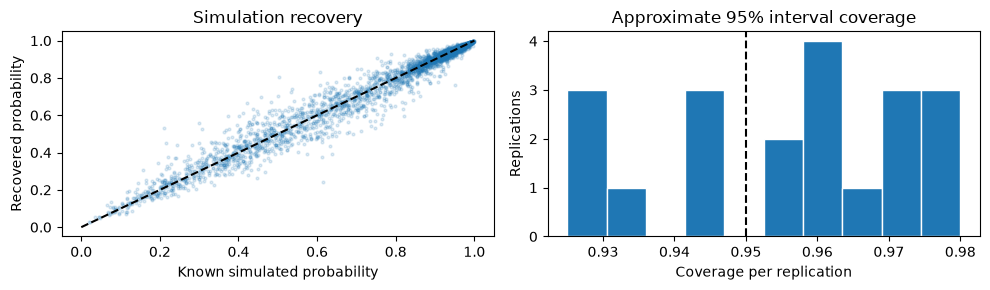

In [18]:
diagnostic_rng = np.random.default_rng(45)
prior_draws = diagnostic_rng.normal(size=(contact_model.n_parameters, 500)) / np.sqrt(contact_model.precision[:, None])
prior_context_frame = pd.DataFrame(CONTEXT_LEVELS, columns=CONTEXT)
prior_design = contact_model.design_matrix(prior_context_frame, neutral_batter=True, neutral_pitcher=True)
prior_probabilities = expit(prior_design @ prior_draws)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(prior_probabilities.ravel(), bins=30, edgecolor="white")
ax.set(xlabel="Prior contact probability", ylabel="Draw/context combinations", title="Working prior predictive probabilities")
plt.show()
print("Prior probability quantiles:", np.quantile(prior_probabilities, [0.01, 0.5, 0.99]))

recovery = simulation_recovery(contact_model, development, SIMULATION_REPETITIONS, seed=46)
recovery["sample_band"] = pd.cut(recovery.swing_count, bins=[0, 50, 200, np.inf], labels=["<50", "50–199", "200+"], right=False)
recovery_summary = recovery.groupby("sample_band", observed=True).agg(
    estimates=("covered_95", "size"), coverage_95=("covered_95", "mean"),
    mean_error=("error", "mean"), mean_interval_width=("interval_width", "mean"),
)
display(recovery_summary)
if recovery.covered_95.mean() < 0.90:
    print("Approximate intervals under-cover in recovery simulation; interpret cautiously and revisit the approximation.")
replication_coverage = recovery.groupby("replication").covered_95.mean()
print("Coverage across replications:")
display(replication_coverage.describe())
recovery.to_csv(output_dir / "simulation_recovery.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].scatter(recovery.true_probability, recovery.estimated_probability, s=4, alpha=0.15)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(xlabel="Known simulated probability", ylabel="Recovered probability", title="Simulation recovery")
axes[1].hist(replication_coverage, bins=10, edgecolor="white")
axes[1].axvline(0.95, color="black", linestyle="--")
axes[1].set(xlabel="Coverage per replication", ylabel="Replications", title="Approximate 95% interval coverage")
fig.tight_layout()
plt.show()

### Protected test evaluation across the complete context grid

Everything above, including model settings, is frozen before computing these scores. Score actual batter–pitcher predictions, not neutral-opponent projections. Report proper scores, discrimination, sample sizes, and batter-balanced scores. Evaluate all 16 contexts plus marginal splits, training sample-size bands, and the three requested settings. Test findings are assessment; revising the model afterward would require a new evaluation design.

,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
Overall,9895.0,0.668870,0.237958,0.500000,0.667154,0.237112,0.610005,0.602294,0.007711
Context,9895.0,0.558675,0.190625,0.749054,0.568961,0.194610,0.610005,0.602259,0.007746
Context + batter,9895.0,0.514952,0.172114,0.808920,0.525980,0.176277,0.610005,0.603811,0.006194
Context + batter + pitcher,9895.0,0.446299,0.145589,0.863464,0.458600,0.150197,0.610005,0.605748,0.004258


swings  log_loss     brier   roc_auc  \
bat_side throw_side is_in_zone is_fb                                         
L        L          0          0         167  0.551395  0.189102  0.752896   
                               1         168  0.595828  0.207530  0.726531   
                    1          0         109  0.508783  0.168290  0.821736   
                               1         135  0.585644  0.202543  0.745651   
         R          0          0         317  0.372378  0.117494  0.788808   
                               1         472  0.312219  0.092306  0.773599   
                    1          0         788  0.300075  0.087083  0.800883   
                               1        1164  0.232110  0.063610  0.780028   
R        L          0          0         193  0.492839  0.161464  0.781609   
                               1         184  0.523272  0.174710  0.754345   
                    1          0         341  0.329993  0.098596  0.801375   
                               1         418  0.288010  0.083145  0.737163   
         R          0          0        1345  0.499484  0.165029  0.811945   
                               1        1694  0.527541  0.177658  0.804698   
                    1          0         971  0.577867  0.198278  0.763577   
                               1        1429  0.536385  0.180448  0.804480   

                                      batter_balanced_log_loss  \
bat_side throw_side is_in_zone is_fb                             
L        L          0          0                      0.574769   
                               1                      0.592013   
                    1          0                      0.478109   
                               1                      0.566065   
         R          0          0                      0.372245   
                               1                      0.351376   
                    1          0                      0.289940   
                               1                      0.319436   
R        L          0          0                      0.466292   
                               1                      0.516767   
                    1          0                      0.367258   
                               1                      0.368587   
         R          0          0                      0.556550   
                               1                      0.538849   
                    1          0                      0.588695   
                               1                      0.520412   

                                      batter_balanced_brier  observed  \
bat_side throw_side is_in_zone is_fb                                    
L        L          0          0                   0.198673  0.335329   
                               1                   0.207689  0.416667   
                    1          0                   0.157004  0.376147   
                               1                   0.193405  0.437037   
         R          0          0                   0.114381  0.832808   
                               1                   0.104914  0.883475   
                    1          0                   0.084224  0.874365   
                               1                   0.091156  0.920962   
R        L          0          0                   0.150916  0.699482   
                               1                   0.171492  0.706522   
                    1          0                   0.112022  0.853372   
                               1                   0.110323  0.906699   
         R          0          0                   0.188291  0.362825   
                               1                   0.182748  0.429752   
                    1          0                   0.200966  0.496395   
                               1                   0.173413  0.514346   

                                      predicted  observed_minus_predicted  
bat_side throw_side is_in_zone is_fb                 

Marginal split: bat_side


,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
bat_side,,,,,,,,,
L,3320,0.330948,0.101087,0.867679,0.349589,0.107262,0.803614,0.801720,0.001895
R,6575,0.504544,0.168059,0.830598,0.514757,0.172315,0.512243,0.506793,0.005451


Marginal split: throw_side


...

Batter training sample-size bands:


,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
sample_band,,,,,,,,,
<50,384,0.459976,0.148313,0.846658,0.485488,0.161696,0.653646,0.621154,0.032492
50–199,3770,0.454401,0.148660,0.858836,0.459137,0.149706,0.601326,0.601714,-0.000388
200+,5741,0.440064,0.143389,0.867287,0.440828,0.143748,0.612785,0.607366,0.005419


Pitcher training sample-size bands:


,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
sample_band,,,,,,,,,
<50,20,0.370919,0.133506,0.927083,0.370919,0.133506,0.600000,0.700998,-0.100998
50–199,8123,0.447431,0.145994,0.863868,0.454656,0.148836,0.602979,0.601316,0.001663
200+,1752,0.441911,0.143847,0.860302,0.479411,0.158147,0.642694,0.625205,0.017489


,swings,log_loss,brier,roc_auc,batter_balanced_log_loss,batter_balanced_brier,observed,predicted,observed_minus_predicted
IZ,5355.0,0.411143,0.132048,0.864495,0.437424,0.141740,0.699907,0.694359,0.005547
IZ vs LHP,1003.0,0.366336,0.113722,0.862692,0.421296,0.132020,0.767697,0.773691,-0.005995
IZ FB vs LHP,553.0,0.360670,0.112293,0.853871,0.430299,0.136286,0.792043,0.806306,-0.014263


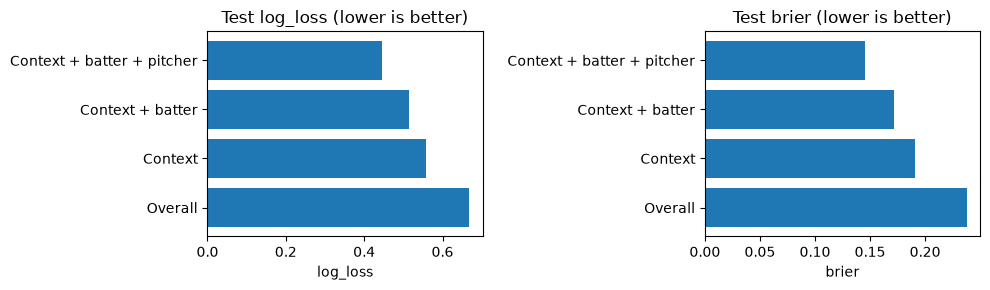

In [19]:
test_predictions = {"Overall": np.full(len(test), development.contact.mean())}
test_predictions.update({name: model.predict(test) for name, model in final_models.items()})
test_scores = pd.DataFrame({name: performance(test, prediction) for name, prediction in test_predictions.items()}).T
display(test_scores)
test_scores.to_csv(output_dir / "test_scores.csv")
heldout_probability = test_predictions["Context + batter + pitcher"]
context_scores = subgroup_performance(test, heldout_probability, CONTEXT)
display(context_scores)
context_scores.to_csv(output_dir / "test_context_scores.csv")
for feature in CONTEXT:
    print(f"Marginal split: {feature}")
    display(subgroup_performance(test, heldout_probability, [feature]))

sample_test = test.assign(training_swings=test.batter_id.map(train.groupby("batter_id").size()))
sample_test["sample_band"] = pd.cut(sample_test.training_swings, bins=[0, 50, 200, np.inf], labels=["<50", "50–199", "200+"], right=False)
print("Batter training sample-size bands:")
display(subgroup_performance(sample_test, heldout_probability, ["sample_band"]))
pitcher_sample_test = test.assign(training_swings=test.pitcher_id.map(train.groupby("pitcher_id").size()))
pitcher_sample_test["sample_band"] = pd.cut(pitcher_sample_test.training_swings, bins=[0, 50, 200, np.inf], labels=["<50", "50–199", "200+"], right=False)
print("Pitcher training sample-size bands:")
display(subgroup_performance(pitcher_sample_test, heldout_probability, ["sample_band"]))

pdf_masks = {
    "IZ": test.is_in_zone.eq(1),
    "IZ vs LHP": test.is_in_zone.eq(1) & test.throw_side.eq("L"),
    "IZ FB vs LHP": test.is_in_zone.eq(1) & test.throw_side.eq("L") & test.is_fb.eq(1),
}
pdf_scores = pd.DataFrame({name: performance(test.loc[mask], heldout_probability[mask]) for name, mask in pdf_masks.items()}).T
display(pdf_scores)
test.assign(predicted_contact=heldout_probability).rename_axis("original_pitch_row").to_csv(output_dir / "test_predictions.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ["log_loss", "brier"]):
    ax.barh(test_scores.index, test_scores[metric])
    ax.set(xlabel=metric, title=f"Test {metric} (lower is better)")
fig.tight_layout()
plt.show()

### Calibration: overall, all 16 contexts, and systematic residuals

Reliability curves compare mean predicted probability with observed contact in equal-frequency bins. Bin counts are shown; small groups use fewer bins (roughly at least 30 observations per bin). These are descriptive curves, not confidence bands. Scores and calibration assess different aspects of performance; ROC AUC cannot establish calibration. No post-hoc calibrator is fit to test data.

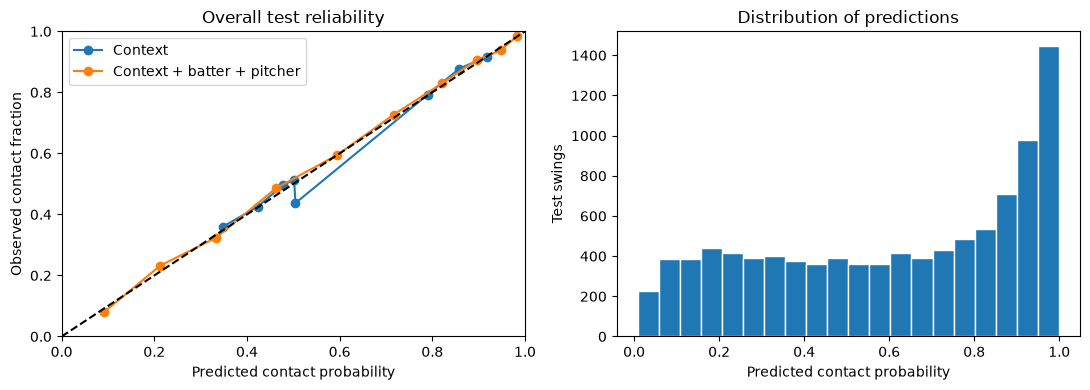

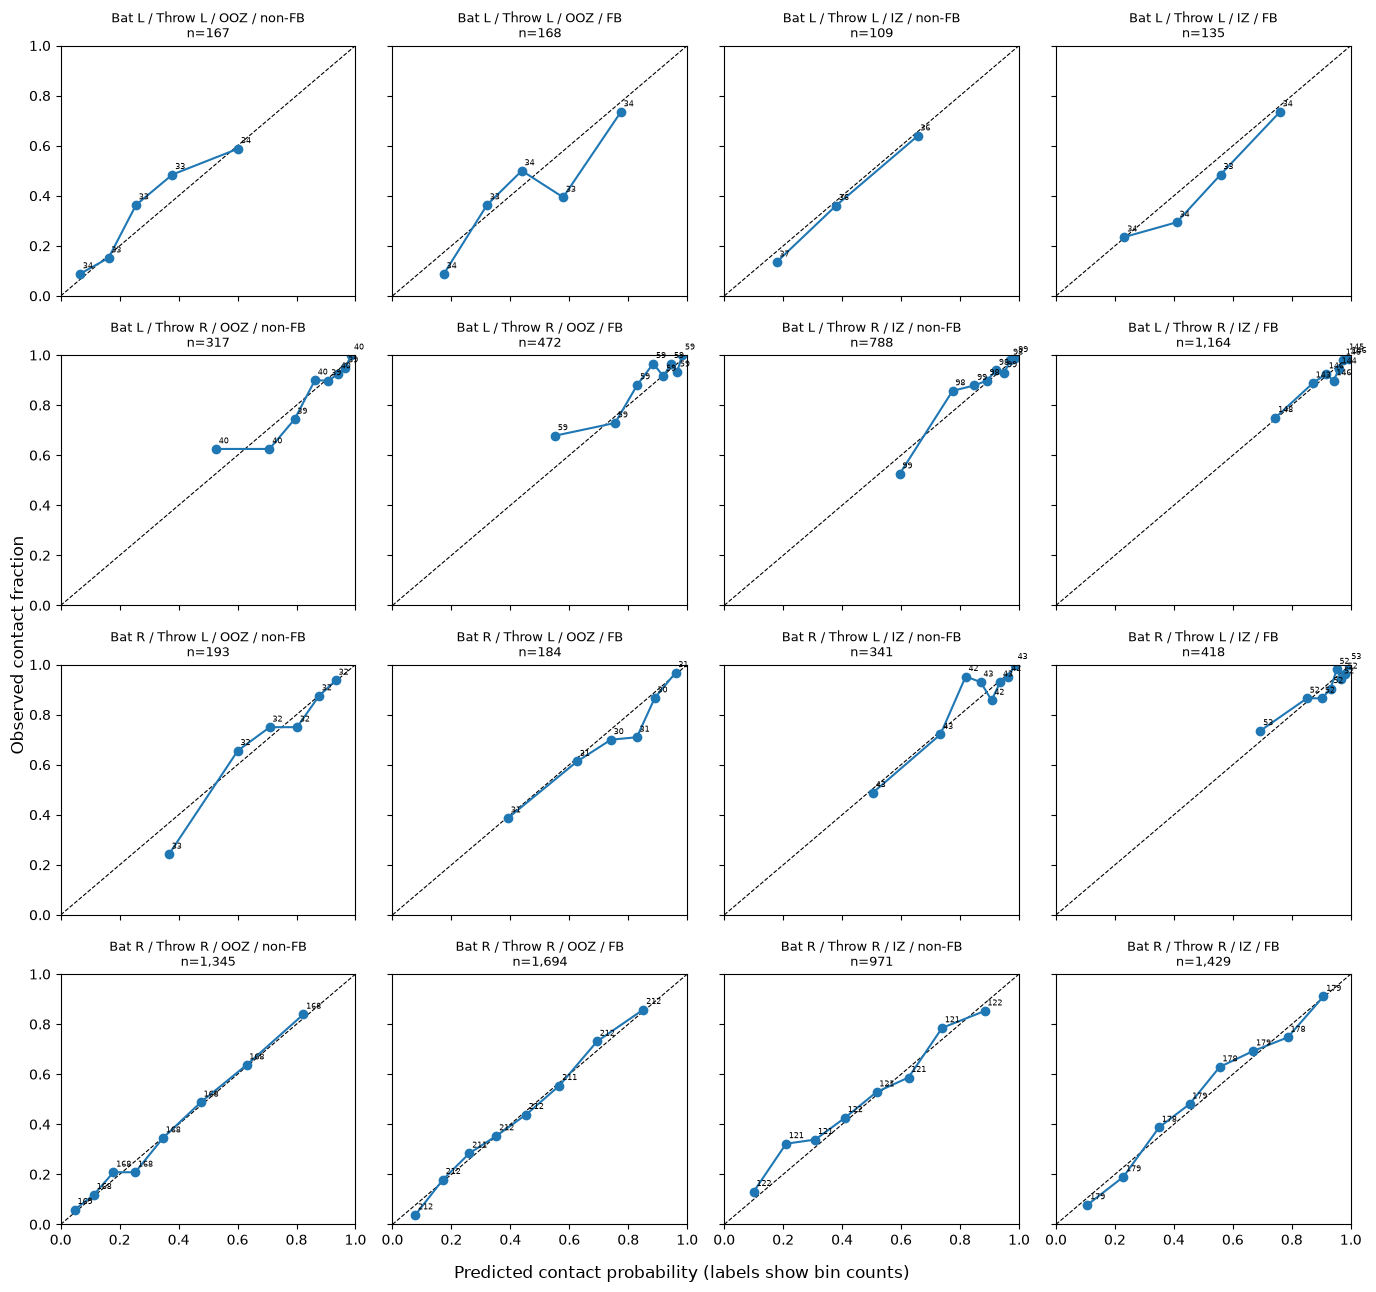

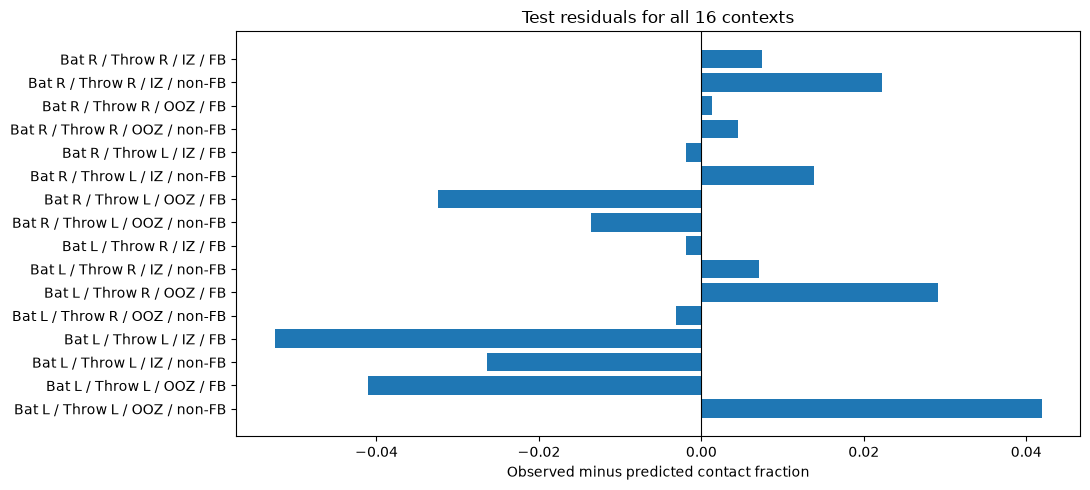

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ["Context", "Context + batter + pitcher"]:
    curve = reliability(test, test_predictions[name])
    axes[0].plot(curve.predicted, curve.observed, "o-", label=name)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted contact probability", ylabel="Observed contact fraction", title="Overall test reliability")
axes[0].legend()
axes[1].hist(heldout_probability, bins=20, edgecolor="white")
axes[1].set(xlabel="Predicted contact probability", ylabel="Test swings", title="Distribution of predictions")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(14, 13), sharex=True, sharey=True)
for ax, context in zip(axes.ravel(), CONTEXT_LEVELS):
    mask = np.ones(len(test), dtype=bool)
    for key, value in zip(CONTEXT, context):
        mask &= test[key].eq(value).to_numpy()
    subset = test.loc[mask]
    curve = reliability(subset, heldout_probability[mask], max_bins=8)
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.plot(curve.predicted, curve.observed, "o-")
    for row in curve.itertuples():
        ax.annotate(str(row.count), (row.predicted, row.observed), fontsize=6, xytext=(2, 4), textcoords="offset points")
    bat, throw, zone, fb = context
    ax.set_title(f"Bat {bat} / Throw {throw} / {'IZ' if zone else 'OOZ'} / {'FB' if fb else 'non-FB'}\nn={len(subset):,}", fontsize=9)
    ax.set(xlim=(0, 1), ylim=(0, 1))
fig.supxlabel("Predicted contact probability (labels show bin counts)")
fig.supylabel("Observed contact fraction")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
labels = [f"Bat {b} / Throw {p} / {'IZ' if z else 'OOZ'} / {'FB' if f else 'non-FB'}" for b, p, z, f in context_scores.index]
ax.barh(labels, context_scores.observed_minus_predicted)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Observed minus predicted contact fraction", title="Test residuals for all 16 contexts")
fig.tight_layout()
plt.show()

### Replicated held-out outcomes

Generate held-out contacts using joint coefficient draws **and Bernoulli outcome noise**. The resulting intervals describe replicated contact fractions over these particular test swings; they are different from intervals for a batter's latent probability. Compare all 16 contexts. This check is conditional on the frozen model and does not trigger test-driven refitting.

swings  observed  replicated_mean  \
bat_side throw_side is_in_zone is_fb                                      
L        L          0          0         167  0.335329         0.295973   
                               1         168  0.416667         0.459985   
                    1          0         109  0.376147         0.403807   
                               1         135  0.437037         0.490537   
         R          0          0         317  0.832808         0.836159   
                               1         472  0.883475         0.854428   
                    1          0         788  0.874365         0.864873   
                               1        1164  0.920962         0.921338   
R        L          0          0         193  0.699482         0.710868   
                               1         184  0.706522         0.736046   
                    1          0         341  0.853372         0.837427   
                               1         418  0.906699         0.905353   
         R          0          0        1345  0.362825         0.360173   
                               1        1694  0.429752         0.428858   
                    1          0         971  0.496395         0.474356   
                               1        1429  0.514346         0.506912   

                                      lower_95  upper_95  \
bat_side throw_side is_in_zone is_fb                       
L        L          0          0      0.233533  0.359431   
                               1      0.380952  0.541815   
                    1          0      0.320642  0.495642   
                               1      0.399815  0.570370   
         R          0          0      0.794953  0.876972   
                               1      0.819915  0.887765   
                    1          0      0.841371  0.889594   
                               1      0.903780  0.936426   
R        L          0          0      0.647668  0.772021   
                               1      0.673913  0.804348   
                    1          0      0.794721  0.873900   
                               1      0.873206  0.935407   
         R          0          0      0.334535  0.386617   
                               1      0.407320  0.451018   
                    1          0      0.445906  0.508754   
                               1      0.483555  0.531158   

                                      within_predictive_interval  
bat_side throw_side is_in_zone is_fb                              
L        L          0          0                            True  
                               1                            True  
                    1          0                            True  
                               1                            True  
         R          0          0                            True  
                               1                            True  
                    1          0                            True  
                               1                            True  
R        L          0          0                            True  
                               1                            True  
                    1          0                            True  
                               1                            True  
         R          0          0                            True  
                               1                            True  
                    1          0                            True  
                               1                            True

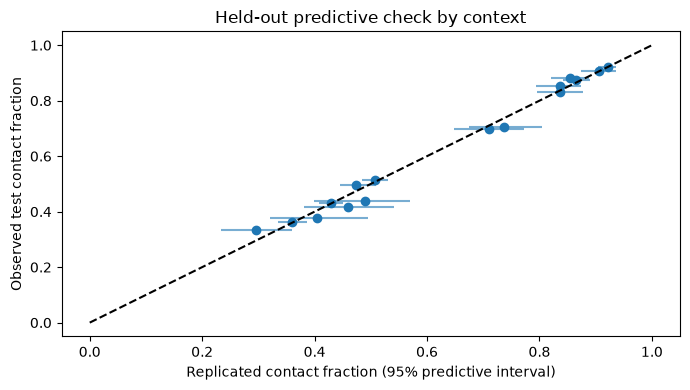

In [21]:
predictive_check = predictive_context_check(contact_model, test, coefficient_draws[:, :400], seed=47)
display(predictive_check)
predictive_check.to_csv(output_dir / "test_predictive_context_check.csv")
fig, ax = plt.subplots(figsize=(7, 4))
x = predictive_check.replicated_mean.to_numpy()
y = predictive_check.observed.to_numpy()
ax.hlines(y, predictive_check.lower_95, predictive_check.upper_95, alpha=0.6)
ax.scatter(x, y)
ax.plot([0, 1], [0, 1], "k--")
ax.set(xlabel="Replicated contact fraction (95% predictive interval)", ylabel="Observed test contact fraction", title="Held-out predictive check by context")
fig.tight_layout()
plt.show()

### Shrinkage and uncertainty by sample size

The first comparison uses a raw **logit effect relative to the fitted context baseline**, which makes regression toward the mean more interpretable than comparing raw and standardized probabilities with different pitch mixes. The raw estimate still contains historical opponent composition; the fitted effect adjusts for pitcher quality. The second plot compares raw IZ FB/LHP rates with neutral-pitcher projections and should therefore be read as both shrinkage and context/opposition adjustment. The interval-width plot examines the fully conditioned PDF target; uncertainty also depends on opposition and context coverage, not just total sample size.

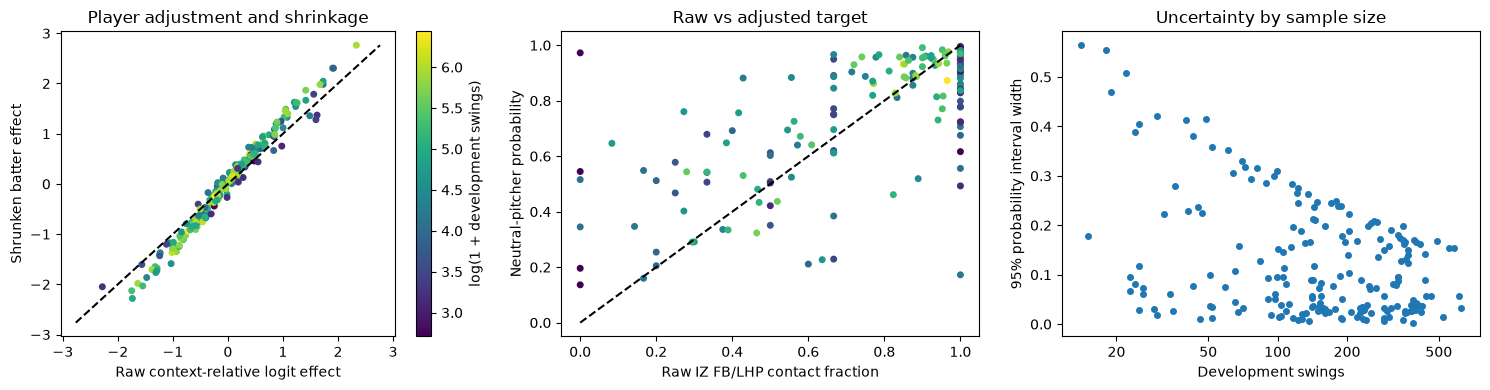

In [22]:
batter_effects = contact_model.player_effects("batter_id")
context_logits = contact_model.theta[:16]
context_number = (development.bat_side.eq("R").astype(int) * 8 + development.throw_side.eq("R").astype(int) * 4 + development.is_in_zone * 2 + development.is_fb)
raw_players = development.assign(population_probability=expit(context_logits[context_number.to_numpy()])).groupby("batter_id").agg(contacts=("contact", "sum"), swings=("contact", "size"), context_mean=("population_probability", "mean"))
# Jeffreys-style 0.5 correction prevents infinite logits for raw 0/1 rates.
raw_probability = (raw_players.contacts + 0.5) / (raw_players.swings + 1)
raw_effect = np.log(raw_probability / (1 - raw_probability)) - np.log(raw_players.context_mean / (1 - raw_players.context_mean))
raw_effect -= raw_effect.groupby(batter_effects.side).transform("mean")

# Internal diagnostics only: the user-facing output below is a single-batter lookup.
projection_rows = []
for player_id in contact_model.player_ids["batter_id"]:
    projection = batter_projection(contact_model, int(player_id), reference_mix, coefficient_draws)
    last = projection.iloc[-1]
    projection_rows.append({"batter_id": player_id, **last.to_dict()})
projection_diagnostics = pd.DataFrame(projection_rows).set_index("batter_id")
projection_diagnostics["training_swings"] = development.groupby("batter_id").size()
raw_target = development.loc[development.is_in_zone.eq(1) & development.is_fb.eq(1) & development.throw_side.eq("L")].groupby("batter_id").contact.agg(["mean", "size"])
projection_diagnostics["raw_contact"] = raw_target["mean"]
projection_diagnostics["target_swings"] = raw_target["size"].fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
points = axes[0].scatter(raw_effect, batter_effects.effect, c=np.log1p(batter_effects.swing_count), cmap="viridis", s=16)
limit = max(abs(raw_effect).max(), abs(batter_effects.effect).max())
axes[0].plot([-limit, limit], [-limit, limit], "k--")
axes[0].set(xlabel="Raw context-relative logit effect", ylabel="Shrunken batter effect", title="Player adjustment and shrinkage")
fig.colorbar(points, ax=axes[0], label="log(1 + development swings)")
axes[1].scatter(projection_diagnostics.raw_contact, projection_diagnostics.contact_probability, c=np.log1p(projection_diagnostics.target_swings), cmap="viridis", s=16)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set(xlabel="Raw IZ FB/LHP contact fraction", ylabel="Neutral-pitcher probability", title="Raw vs adjusted target")
axes[2].scatter(projection_diagnostics.training_swings, projection_diagnostics.upper_95 - projection_diagnostics.lower_95, s=16)
axes[2].set(xscale="log", xlabel="Development swings", ylabel="95% probability interval width", title="Uncertainty by sample size")
axes[2].set_xticks([20, 50, 100, 200, 500], ["20", "50", "100", "200", "500"])
axes[2].minorticks_off()
fig.tight_layout()
plt.show()

### Batter lookup: three standardized interview answers

Change only `batter_id` in the following cell and run it. Outputs use the batter's observed batting side, neutral pitcher quality within handedness, and development-set joint pitcher-handedness × FB weights conditioned on batting side. All hitters of the same side share weights; LHH and RHH can have different typical opposition. Intervals condition on that mix and the selected shrinkage settings. Observed counts come from development data used in fitting. Unknown IDs produce an informative message rather than an unsupported player estimate.

Batter 1 | bats R | 141 development swings


,contact_probability,lower_95,upper_95,observed_swings
scenario,,,,
In-zone pitches,54.7%,47.0%,62.7%,58
In-zone pitches vs LHP,90.8%,87.0%,93.6%,13
In-zone fastballs vs LHP,93.4%,90.3%,95.5%,7


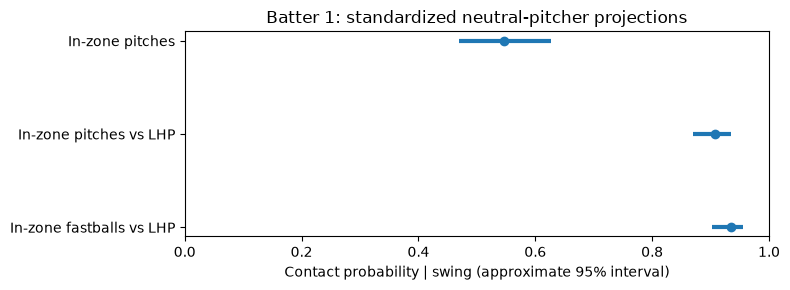

In [23]:
batter_id = 1  # Change this ID and rerun this cell.

try:
    batter_answers = batter_projection(contact_model, batter_id, reference_mix, coefficient_draws)
except ValueError as error:
    print(error)
    print("Choose a known batter ID from the supplied data.")
else:
    player_swings = development.loc[development.batter_id.eq(batter_id)]
    side = player_swings.bat_side.iloc[0]
    masks = [
        player_swings.is_in_zone.eq(1),
        player_swings.is_in_zone.eq(1) & player_swings.throw_side.eq("L"),
        player_swings.is_in_zone.eq(1) & player_swings.throw_side.eq("L") & player_swings.is_fb.eq(1),
    ]
    batter_answers["observed_swings"] = [int(mask.sum()) for mask in masks]
    print(f"Batter {batter_id} | bats {side} | {len(player_swings):,} development swings")
    display(batter_answers.style.format({"contact_probability": "{:.1%}", "lower_95": "{:.1%}", "upper_95": "{:.1%}"}))
    fig, ax = plt.subplots(figsize=(8, 3))
    positions = np.arange(len(batter_answers))
    ax.hlines(positions, batter_answers.lower_95, batter_answers.upper_95, linewidth=3)
    ax.scatter(batter_answers.contact_probability, positions)
    ax.set_yticks(positions, batter_answers.index)
    ax.invert_yaxis()
    ax.set(xlim=(0, 1), xlabel="Contact probability | swing (approximate 95% interval)", title=f"Batter {batter_id}: standardized neutral-pitcher projections")
    fig.tight_layout()
    plt.show()

### Opponent-quality and neutral-batter examples

Hold the hitter and pitch context fixed while changing the pitcher. The converse holds pitcher/context fixed and varies batters. These comparisons illustrate jointly adjusted player quality. They are predictive associations, not causal estimates; neutral-opponent projections are not expected to equal raw rates against historical opposition.

,pitcher_id,pitcher_contact_effect,batter_contact_probability
0,64,-2.285259,0.591754
1,197,0.033984,0.936462
2,94,1.444991,0.983721


Same batter vs neutral LHP: 0.9344093559875816


,bat_side,pitcher_id,throw_side,is_in_zone,is_fb,neutral_batter_contact_probability
0,L,197,L,1,1,0.512991
1,R,197,L,1,1,0.947545


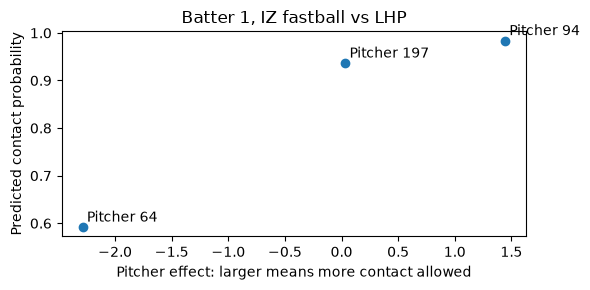

In [24]:
example_batter_id = 1
example_batter_side = development.loc[development.batter_id.eq(example_batter_id), "bat_side"].iloc[0]
pitcher_effects = contact_model.player_effects("pitcher_id")
example_pitchers = pitcher_effects.loc[pitcher_effects.side.eq("L")].sort_values("effect")
chosen_pitcher_ids = example_pitchers.iloc[[0, len(example_pitchers) // 2, -1]].index
matchups = pd.DataFrame({"batter_id": example_batter_id, "bat_side": example_batter_side, "pitcher_id": chosen_pitcher_ids, "throw_side": "L", "is_in_zone": 1, "is_fb": 1})
quality_example = matchups[["pitcher_id"]].copy()
quality_example["pitcher_contact_effect"] = pitcher_effects.loc[chosen_pitcher_ids, "effect"].to_numpy()
quality_example["batter_contact_probability"] = contact_model.predict(matchups)
display(quality_example)
print("Same batter vs neutral LHP:", contact_model.predict(matchups.iloc[:1], neutral_pitcher=True)[0])

neutral_batter_rows = pd.DataFrame({"bat_side": ["L", "R"], "pitcher_id": chosen_pitcher_ids[1], "throw_side": "L", "is_in_zone": 1, "is_fb": 1})
neutral_batter_rows["neutral_batter_contact_probability"] = contact_model.predict(neutral_batter_rows, neutral_batter=True)
display(neutral_batter_rows)
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(quality_example.pitcher_contact_effect, quality_example.batter_contact_probability)
for row in quality_example.itertuples():
    ax.annotate(f"Pitcher {row.pitcher_id}", (row.pitcher_contact_effect, row.batter_contact_probability), xytext=(3, 4), textcoords="offset points")
ax.set(xlabel="Pitcher effect: larger means more contact allowed", ylabel="Predicted contact probability", title=f"Batter {example_batter_id}, IZ fastball vs LHP")
fig.tight_layout()
plt.show()

### Draft writeup (editable)

**Approach.** Estimate contact conditional on a swing, with all four observed pitch-context features present from the start. A 16-context population component captures the provided platoon, zone, and fastball patterns. Shared batter and pitcher effects estimate player quality jointly and regress sparse players toward population context performance. The data are taken as ground truth; no correction is applied to the unexpected contact patterns.

**Evaluation.** Tune Gaussian shrinkage on validation log loss using individual-covered 60/20/20 partitions. Preserve a test set that never enters fitting, tuning, reference weights, or recalibration. Assess all 16 contexts, marginal groups, player sample-size bands, proper scores, and reliability curves. Pair-grouped development scoring is a sensitivity check, not an additional untouched holdout. There is no chronological forecast test because dates are absent.

**Interview answers.** The lookup cell returns the three requested contact probabilities for any observed batter. Predictions use neutral pitcher quality within handedness and a historical in-zone swing-context mix shared within batting side. The mix preserves the joint pitcher-handedness × fastball distribution for LHH and RHH separately, so their typical exposure to LHP can differ. These are standardized ability estimates, not estimates of a hitter's future pitch selection. Mixtures average probabilities rather than logits.

**Uncertainty.** Joint Laplace coefficient draws propagate population and player uncertainty into probability intervals. Their first-principles basis is a local quadratic approximation to the specified posterior. These intervals are conditional on selected precision, architecture, and reference weights. Sparse-player simulation recovery and predictive replications assess the approximation under the assumed hierarchy; they cannot establish coverage under selection effects, changing ability, or omitted pitch traits. Future outcome counts also require Bernoulli variation.

**Additional information desired.** Dates, game and plate-appearance IDs would support temporal and dependence-aware validation. Count, exact location, velocity, movement, pitch classification, player history/age, injuries, and the intended future opponent mix would support better adjustment and forecasting. The observed sample may not represent MLB as a whole; taking its labels as ground truth does not establish population representativeness.

**Future improvements.** With more data and a reason to refine the model, add shrunken batter- and/or pitcher-specific responses to platoon, fastballs, or zone. Consider dynamic ability and richer pitch traits. Model swing decisions separately if the goal expands to future contact per pitch or player-specific future swing-context mixtures. Assess how much uncertainty changes when shrinkage and reference weights are estimated rather than conditioned on. Player-specific context slopes are intentionally absent from this implementation.

**Another interesting question.** Do hitters have persistent differences in fastball versus non-fastball contact ability after adjusting for platoon and pitcher quality? That would motivate a future partially pooled context-slope model.

The following cell writes a short, results-based paragraph so the draft is accompanied by actual run evidence. Revise the prose above and this interpretation as desired.

In [25]:
full_name = "Context + batter + pitcher"
context_loss = test_scores.loc["Context", "log_loss"]
full_loss = test_scores.loc[full_name, "log_loss"]
coverage = recovery.covered_95.mean()
max_residual = context_scores.observed_minus_predicted.abs().max()
results_note = (
    f"The held-out context-only log loss was {context_loss:.4f}, compared with {full_loss:.4f} "
    f"for the jointly adjusted player model. Its Brier score was {test_scores.loc[full_name, 'brier']:.4f}. "
    f"The largest absolute observed-minus-predicted difference among the 16 contexts was {max_residual:.3f}. "
    f"Model-conditional recovery simulation covered {coverage:.1%} of the evaluated player targets "
    f"across {SIMULATION_REPETITIONS} replications; replication-level summaries above reflect shared uncertainty. "
    "These scores assess held-out swings involving observed players, not future-season performance. "
    "Individual player probabilities and approximate intervals are available in the batter lookup cell."
)
print(results_note)
(output_dir / "results_note.txt").write_text(results_note + "\n")

The held-out context-only log loss was 0.5587, compared with 0.4463 for the jointly adjusted player model. Its Brier score was 0.1456. The largest absolute observed-minus-predicted difference among the 16 contexts was 0.053. Model-conditional recovery simulation covered 95.5% of the evaluated player targets across 20 replications; replication-level summaries above reflect shared uncertainty. These scores assess held-out swings involving observed players, not future-season performance. Individual player probabilities and approximate intervals are available in the batter lookup cell.


589

Using this as a space to note other ideas that I'll want to include in my writeup:

Desire for data/game info so that proper future projection can be done rather than just on unseen pitches

Figure out what's going on with the platoon-biased contact rates

Have pitch-level stuff features so that we can baseline to pitch stuff rather than just pitcher quality

Larger data set to allow for more sophisticated models like a KL divergence loss driven NN (similar to that in PIT)

Consider adding player-specific context logits (e.g., bigger platoon effect for given batter)

Discuss different forms of uncertainty that are present in this problem (model vs observational)

Desired integration with a P(swing) model